In [1]:
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt

M = 0.5       # Масса тележки
m = 0.2       # Масса маятника
l = 0.3       # Длина маятника
g = 9.81

F_MAX = 15.0  # Максимальная сила по модулю

Параметры PSO:

In [2]:
n_particles = 30
dim = 3                  # kp, ki, kd
n_iterations = 60

w = 0.7
c1 = 1.5
c2 = 1.5

In [3]:
# Границы параметров PID
bounds = np.array([
    [0.0, 100.0],    # kp
    [0.0, 50.0],     # ki
    [0.0, 50.0]      # kd
])


Динамика системы описывается уравнениями:
$$
\begin{cases}
\dot{x} = v \\
\dot{v} = \frac{1}{M + m \sin^2\theta} \left( m \sin\theta \cos\theta (g - L \omega^2) + F \right) \\
\dot{\theta} = \omega \\
\dot{\omega} = \frac{1}{M + m \sin^2\theta} \left( (M + m) \frac{g}{L} \sin\theta - m \sin\theta \cos\theta \omega^2 + \frac{\cos\theta}{L} F \right)
\end{cases}
$$

In [4]:
def pendulum_dynamics(t, state, kp, ki, kd):

    x, v, theta, omega, integral = state

    # PID-регулятор
    F = -(kp * theta + ki * integral + kd * omega)

    # Ограничение управления
    F = np.clip(F, -F_MAX, F_MAX)

    sin_t = np.sin(theta)
    cos_t = np.cos(theta)

    denom = M + m * sin_t**2

    dx = v

    dv = (
        m * sin_t * (g * cos_t - l * omega**2)
        + F
    ) / denom

    dtheta = omega

    domega = (
        (M + m) * g * sin_t
        - m * l * omega**2 * sin_t * cos_t
        + cos_t * F
    ) / (l * denom)

    dintegral = theta

    return [dx, dv, dtheta, domega, dintegral]

In [5]:
def fitness(pid_params):

    kp, ki, kd = pid_params

    theta_tests = [
        -np.pi / 4,
        -np.pi / 8,
        np.pi / 8,
        np.pi / 4
    ]

    total_cost = 0.0

    for theta0 in theta_tests:

        y0 = [0.0, 0.0, theta0, 0.0, 0.0]

        t_span = (0, 10)
        t_eval = np.linspace(0, 10, 1000)

        try:

            sol = solve_ivp(
                pendulum_dynamics,
                t_span,
                y0,
                args=(kp, ki, kd),
                t_eval=t_eval,
                method='RK45'
            )

            if not sol.success:
                return 1e6

            x = sol.y[0]
            theta = sol.y[2]

            # RMS ошибка по углу
            theta_rms = np.sqrt(np.mean(theta**2))

            # Финальное смещение тележки
            final_position = np.abs(x[-1])

            # Штраф за выход угла
            penalty = 0.0

            if np.max(np.abs(theta)) > np.pi / 2:
                penalty += 1000

            # Функционал качества
            cost = (
                100 * theta_rms
                + 10 * final_position
                + penalty
            )

            total_cost += cost

        except:
            return 1e6

    return total_cost

In [6]:
# Инициализация роя

positions = np.random.uniform(
    bounds[:, 0],
    bounds[:, 1],
    (n_particles, dim)
)

velocities = np.random.uniform(
    -1,
    1,
    (n_particles, dim)
)

# Личные лучшие позиции

pbest_positions = positions.copy()

pbest_scores = np.array([
    fitness(p) for p in positions
])

In [7]:
best_history = []

for iteration in range(n_iterations):

    for i in range(n_particles):

        # Ring topology
        # Соседи: i-1, i, i+1

        left = (i - 1) % n_particles
        right = (i + 1) % n_particles

        neighbors = [left, i, right]

        neighbor_scores = np.array([
            pbest_scores[j] for j in neighbors
        ])

        best_neighbor_idx = neighbors[
            np.argmin(neighbor_scores)
        ]

        local_best = pbest_positions[best_neighbor_idx]

        # Обновление скорости

        r1 = np.random.rand(dim)
        r2 = np.random.rand(dim)

        cognitive = (
            c1 * r1 *
            (pbest_positions[i] - positions[i])
        )

        social = (
            c2 * r2 *
            (local_best - positions[i])
        )

        velocities[i] = (
            w * velocities[i]
            + cognitive
            + social
        )

        # Обновление позиции
        positions[i] += velocities[i]

        # Ограничение диапазона
        positions[i] = np.clip(
            positions[i],
            bounds[:, 0],
            bounds[:, 1]
        )

        # Оценка новой позиции

        current_score = fitness(positions[i])

        if current_score < pbest_scores[i]:

            pbest_scores[i] = current_score
            pbest_positions[i] = positions[i].copy()

    # Лучшее решение в рое
    best_particle = np.argmin(pbest_scores)

    best_score = pbest_scores[best_particle]

    best_history.append(best_score)

    print(
        f"Iteration {iteration+1}/{n_iterations}, "
        f"Best Cost = {best_score:.6f}"
    )

Iteration 1/60, Best Cost = 70.072709
Iteration 2/60, Best Cost = 59.037431
Iteration 3/60, Best Cost = 59.037431
Iteration 4/60, Best Cost = 59.037431
Iteration 5/60, Best Cost = 59.037431
Iteration 6/60, Best Cost = 57.732059
Iteration 7/60, Best Cost = 57.732059
Iteration 8/60, Best Cost = 57.732059
Iteration 9/60, Best Cost = 57.732059
Iteration 10/60, Best Cost = 57.536946
Iteration 11/60, Best Cost = 57.536946
Iteration 12/60, Best Cost = 57.536946
Iteration 13/60, Best Cost = 57.536946
Iteration 14/60, Best Cost = 57.536946
Iteration 15/60, Best Cost = 55.064755
Iteration 16/60, Best Cost = 55.064755
Iteration 17/60, Best Cost = 55.064755
Iteration 18/60, Best Cost = 55.064755
Iteration 19/60, Best Cost = 55.064755
Iteration 20/60, Best Cost = 55.064755
Iteration 21/60, Best Cost = 55.064755
Iteration 22/60, Best Cost = 55.064755
Iteration 23/60, Best Cost = 55.064755
Iteration 24/60, Best Cost = 55.064755
Iteration 25/60, Best Cost = 55.064755
Iteration 26/60, Best Cost = 55.06

In [8]:
best_idx = np.argmin(pbest_scores)

best_pid = pbest_positions[best_idx]

kp_best, ki_best, kd_best = best_pid

print("\nЛучшие параметры PID:")

print(f"kp = {kp_best:.4f}")
print(f"ki = {ki_best:.4f}")
print(f"kd = {kd_best:.4f}")

print(f"\nЛучшее значение функционала = {pbest_scores[best_idx]:.6f}")


Лучшие параметры PID:
kp = 93.9272
ki = 49.7948
kd = 0.6582

Лучшее значение функционала = 54.220665


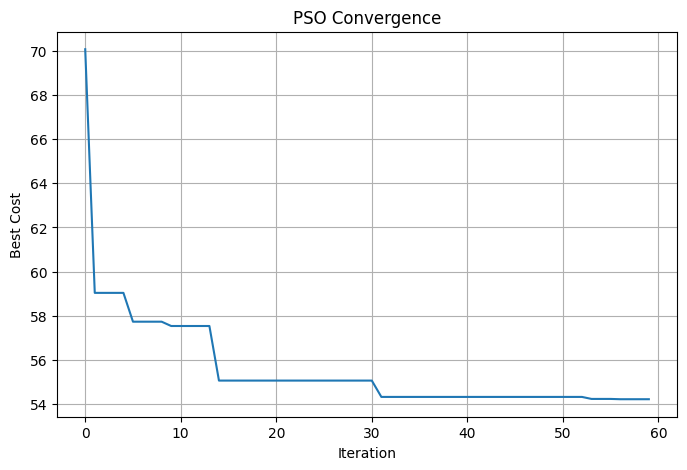

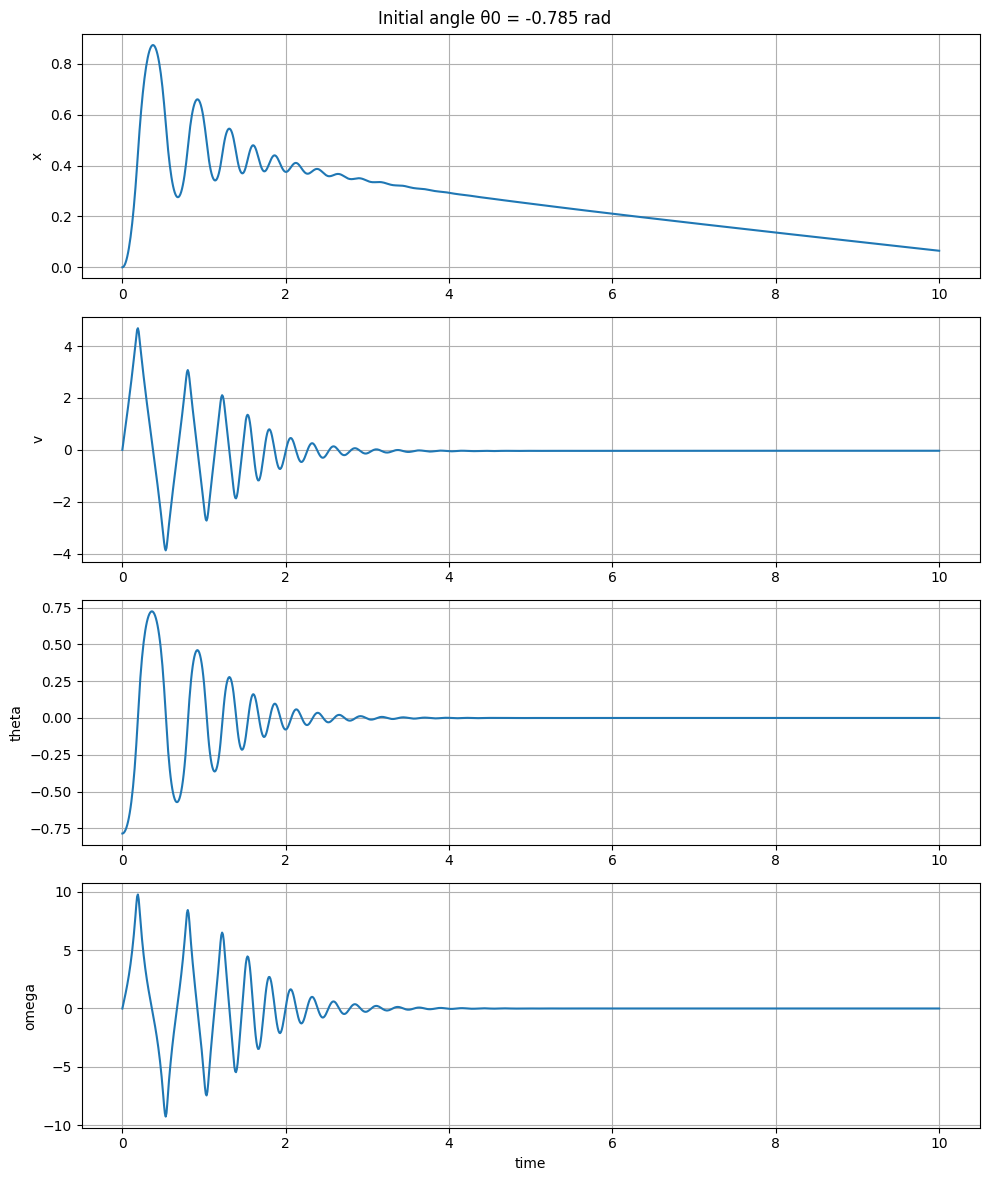

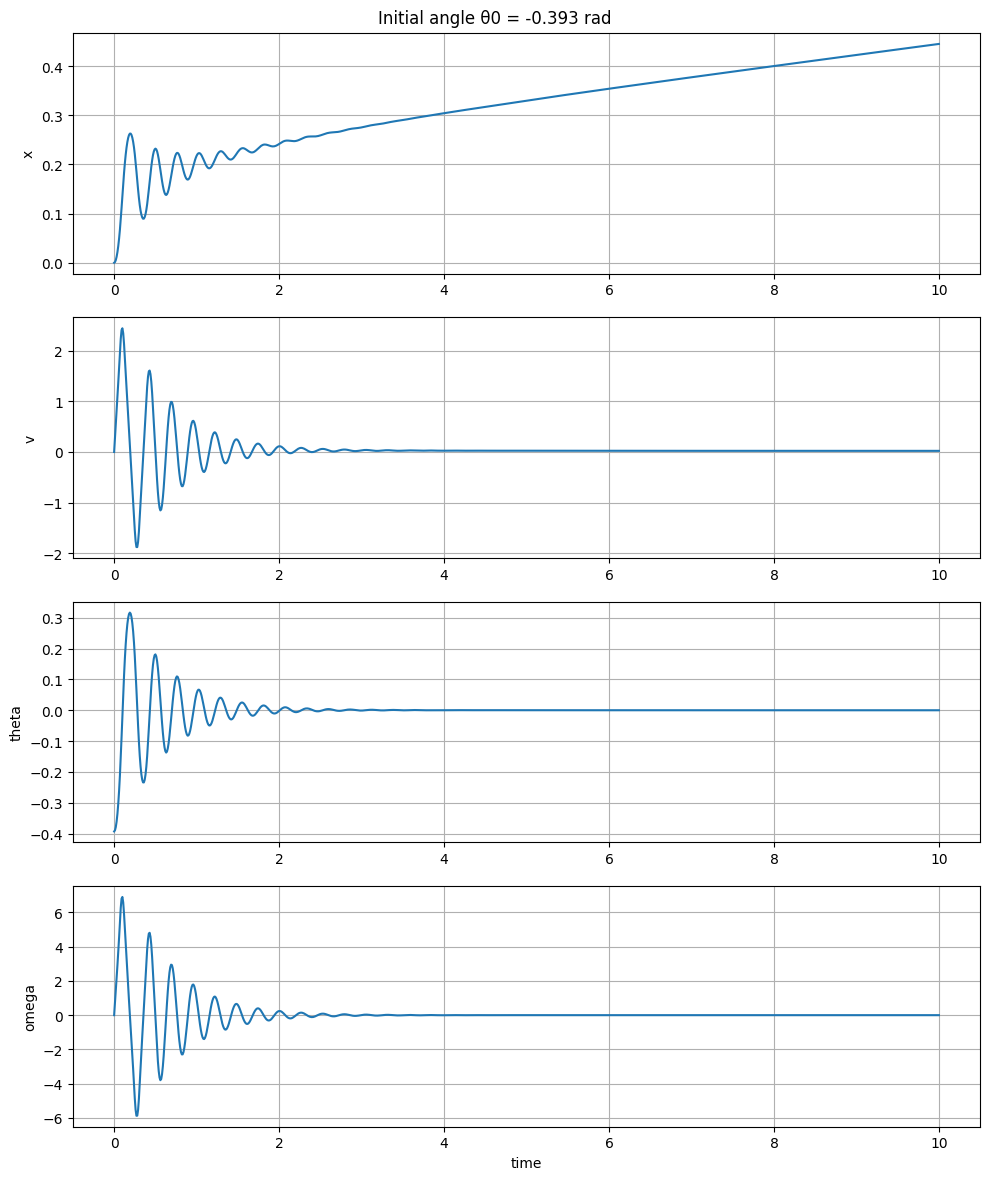

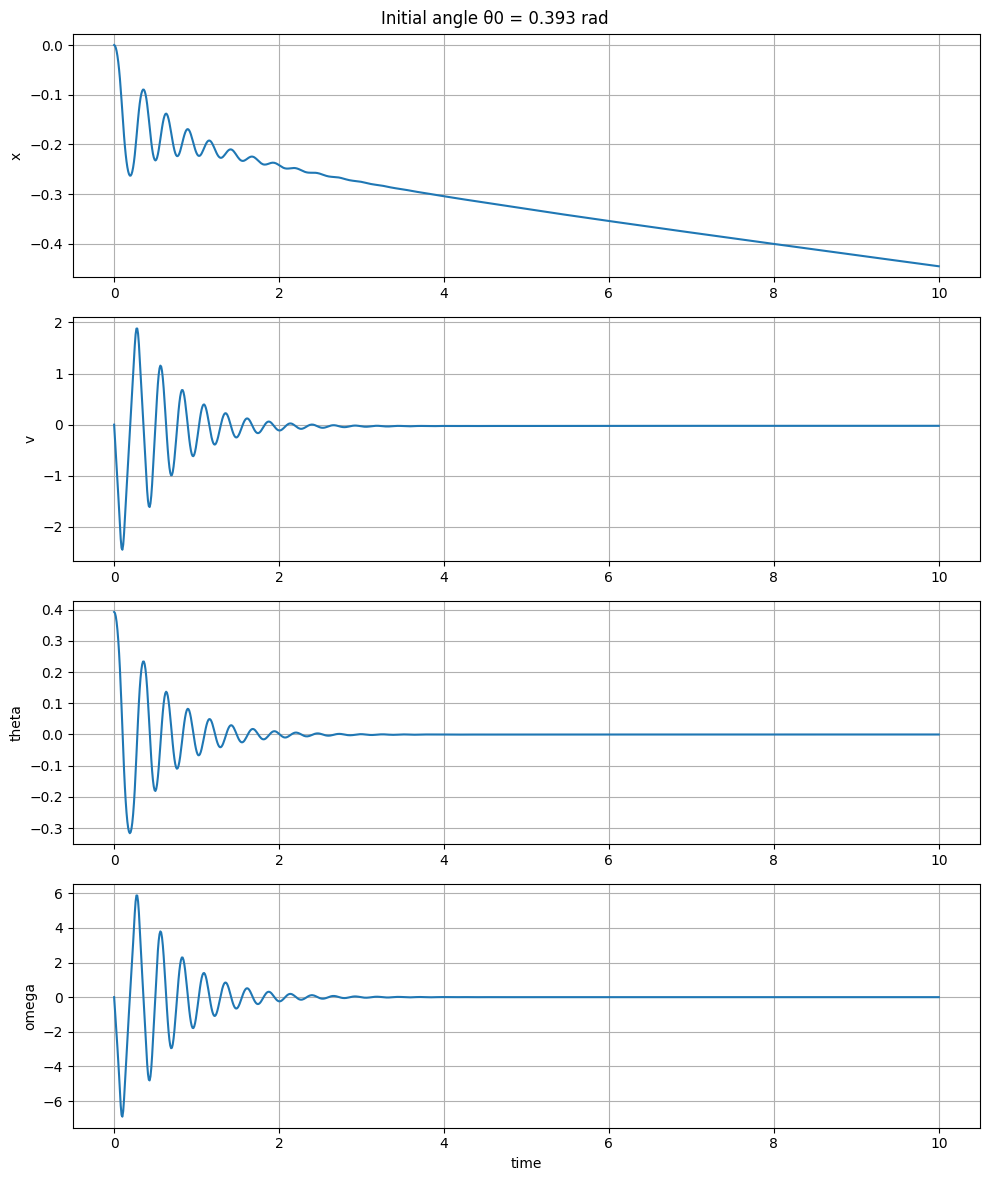

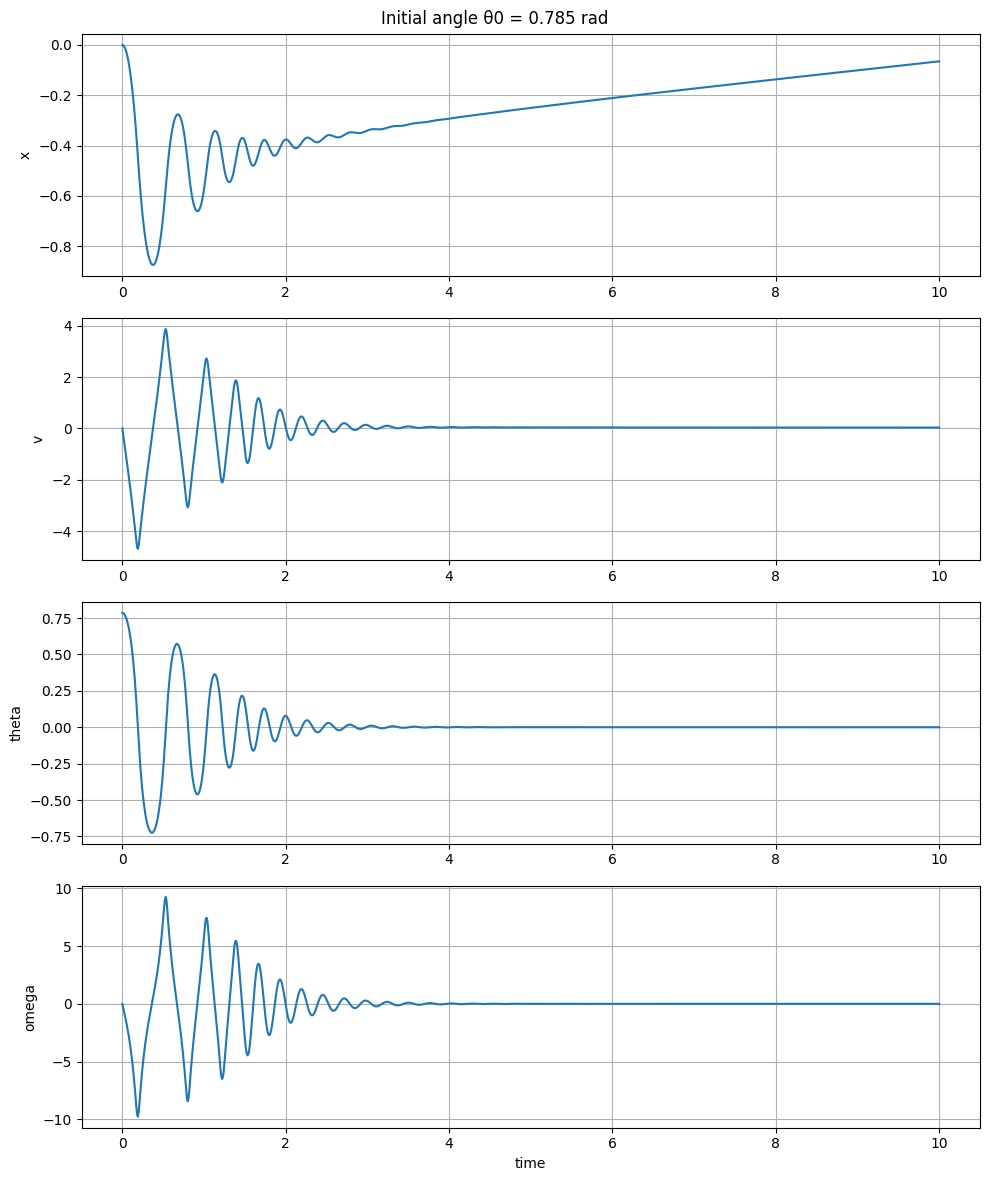

In [9]:

# График сходимости PSO

plt.figure(figsize=(8, 5))

plt.plot(best_history)

plt.xlabel("Iteration")
plt.ylabel("Best Cost")
plt.title("PSO Convergence")

plt.grid()

plt.show()

# Проверка системы

theta_tests = [
    -np.pi / 4,
    -np.pi / 8,
    np.pi / 8,
    np.pi / 4
]

for theta0 in theta_tests:

    y0 = [0.0, 0.0, theta0, 0.0, 0.0]

    t_eval = np.linspace(0, 10, 1000)

    sol = solve_ivp(
        pendulum_dynamics,
        (0, 10),
        y0,
        args=(kp_best, ki_best, kd_best),
        t_eval=t_eval
    )

    t = sol.t

    x = sol.y[0]
    v = sol.y[1]
    theta = sol.y[2]
    omega = sol.y[3]


    fig, axs = plt.subplots(4, 1, figsize=(10, 12))

    fig.suptitle(
        f"Initial angle θ0 = {theta0:.3f} rad"
    )

    axs[0].plot(t, x)
    axs[0].set_ylabel("x")
    axs[0].grid()

    axs[1].plot(t, v)
    axs[1].set_ylabel("v")
    axs[1].grid()

    axs[2].plot(t, theta)
    axs[2].set_ylabel("theta")
    axs[2].grid()

    axs[3].plot(t, omega)
    axs[3].set_ylabel("omega")
    axs[3].set_xlabel("time")
    axs[3].grid()

    plt.tight_layout()

    plt.show()